In [14]:
from sqlalchemy import text
import pandas as pd

from data_access.config import project_path
from data_access.connection import engine


query_path = project_path.query("in_progress_training_dataset.sql")
query = text(query_path.read_text(encoding="utf-8"))

issue_df = pd.read_sql_query(query, engine)
print("Количество строк: ", len(issue_df))

issue_df

Количество строк:  102782


,Issue_ID,Project_ID,Creator_ID,Reporter_ID,Stored_Assignee_ID,Stored_Sprint_ID,Creation_Date,Resolution_Date,Estimation_Date,Snapshot_Type,...,Hours_Since_Last_Status_Change,Hours_Since_Last_Comment,Snapshot_Month,Snapshot_Day_Of_Week,Snapshot_Hour,Description_At_Snapshot,Has_Assignee_At_Snapshot,Has_Sprint_At_Snapshot,Has_Story_Point,Has_Description_At_Snapshot
0,85,1,87.0,87.0,82.0,NaN,2016-02-24 10:51:02,2016-12-23 14:49:45,2016-02-24 10:51:02,in_progress,...,0.0,101.0881,2,0,19,If I try to use <int:message-history/> when de...,1,0,1,1
1,86,1,82.0,82.0,82.0,NaN,2016-02-23 18:31:38,2016-12-23 14:49:26,2016-02-23 18:31:38,in_progress,...,0.0,NaN,5,1,19,"""http://stackoverflow.com/questions/35563064/p...",1,0,1,1
2,89,1,82.0,82.0,82.0,1.0,2016-02-22 15:27:31,2016-02-22 18:41:31,2016-02-22 15:27:31,in_progress,...,0.0,NaN,2,0,15,"Related to XD-2567 which fixed this problem, b...",1,1,1,1
3,90,1,82.0,82.0,88.0,1.0,2016-02-17 14:28:31,2016-02-21 02:28:25,2016-02-17 14:28:31,in_progress,...,0.0,NaN,2,4,18,"""See INT-3956""",1,1,1,1
4,91,1,89.0,89.0,89.0,1.0,2016-02-16 14:59:06,2016-02-19 20:04:19,2016-02-16 14:59:06,in_progress,...,0.0,NaN,2,2,16,"""The following XD components have been identif...",1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102777,508941,33,201059.0,201059.0,201059.0,NaN,2009-06-09 15:07:10,2009-06-09 15:50:44,NaT,in_progress,...,0.0,NaN,6,1,15,,1,0,0,0
102778,508942,33,201059.0,201059.0,201059.0,NaN,2009-06-08 17:27:17,2009-06-09 12:32:17,NaT,in_progress,...,0.0,NaN,6,1,11,"""- change to moreEOO() - create more() - chang...",1,0,0,1
102779,508943,33,201059.0,201059.0,201059.0,NaN,2009-06-06 22:54:31,2009-07-22 18:50:24,NaT,in_progress,...,0.0,1.5514,7,3,17,"""see jstests/index_check3.js""",1,0,0,1
102780,508945,33,201059.0,201059.0,201059.0,NaN,2009-06-04 19:53:19,2009-06-05 09:54:41,NaT,in_progress,...,0.0,NaN,6,4,9,,1,0,0,0


In [15]:
pd.DataFrame(
    {
        "Признак": issue_df.columns,
        "Тип данных": issue_df.dtypes.astype(str).values,
        "Пропусков": issue_df.isna().sum().values,
    }
)

,Признак,Тип данных,Пропусков
0,Issue_ID,int64,0
1,Project_ID,int64,0
2,Creator_ID,float64,359
3,Reporter_ID,float64,654
4,Stored_Assignee_ID,float64,7852
...,...,...,...
76,Description_At_Snapshot,str,1330
77,Has_Assignee_At_Snapshot,int64,0
78,Has_Sprint_At_Snapshot,int64,0
79,Has_Story_Point,int64,0


In [16]:
from data_access.snapshot_dataset import normalize_priority, normalize_type, duration_classes


features = {
    "categorical": ["Project_ID", "Priority_At_Snapshot", "Type_At_Snapshot"],
    "numerical": [
        "Creation_Day_Of_Week",
        "Description_Over_100", "Story_Point_At_Snapshot",
        "Has_Assignee_At_Snapshot",
    ],
    "text": ["Description_And_Comments"],
}

metadata_columns = ["Issue_ID", "Creation_Date", "Snapshot_Date", "Resolution_Date"]
feature_columns = features["categorical"] + features["numerical"] + features["text"]
dataset_df = issue_df.copy()
dataset_df["Priority_At_Snapshot"] = normalize_priority(dataset_df["Priority_At_Snapshot"])
dataset_df["Type_At_Snapshot"] = normalize_type(dataset_df["Type_At_Snapshot"])
description_length = dataset_df["Description_Length_At_Snapshot"]
dataset_df["Description_Over_100"] = (description_length > 100).astype("Int64").where(description_length.notna())

comments = pd.read_sql_query(text("""
    SELECT ID, Issue_ID, Creation_Date, Comment
    FROM Comment
    WHERE Creation_Date >= '2004-01-01'
"""), engine)
comments = comments.merge(
    dataset_df[["Issue_ID", "Creation_Date", "Snapshot_Date"]],
    on="Issue_ID", how="inner", suffixes=("_comment", "_issue"),
)
comments = comments[
    (comments["Creation_Date_comment"] >= comments["Creation_Date_issue"])
    & (comments["Creation_Date_comment"] <= comments["Snapshot_Date"])
].sort_values(["Issue_ID", "Creation_Date_comment", "ID"])
comment_text = comments.groupby("Issue_ID")["Comment"].apply(
    lambda values: "\n".join(values.dropna().astype(str))
)
description = dataset_df["Description_At_Snapshot"]
joined_comments = dataset_df["Issue_ID"].map(comment_text).fillna("")
dataset_df["Description_And_Comments"] = (description.fillna("") + "\n" + joined_comments).str.strip()
dataset_df.loc[dataset_df["Description_Source"] == "invalid_history", "Description_And_Comments"] = pd.NA
dataset_df["Duration_Class"] = duration_classes(dataset_df["Remaining_Duration_Hours"])
dataset_df = dataset_df[metadata_columns + feature_columns + ["Remaining_Duration_Hours", "Duration_Class"]].copy()
dataset_df

,Issue_ID,Creation_Date,Snapshot_Date,Resolution_Date,Project_ID,Priority_At_Snapshot,Type_At_Snapshot,Creation_Day_Of_Week,Description_Over_100,Story_Point_At_Snapshot,Has_Assignee_At_Snapshot,Description_And_Comments,Remaining_Duration_Hours,Duration_Class
0,85,2016-02-24 10:51:02,2016-02-29 19:43:43,2016-12-23 14:49:45,1,P4,Bug,2,1,1.0,1,If I try to use <int:message-history/> when de...,7147.1006,30-365d
1,86,2016-02-23 18:31:38,2016-05-03 19:12:20,2016-12-23 14:49:26,1,P4,Improvement,1,1,1.0,1,"""http://stackoverflow.com/questions/35563064/p...",5611.6183,30-365d
2,89,2016-02-22 15:27:31,2016-02-22 15:49:31,2016-02-22 18:41:31,1,P4,Story,0,1,1.0,1,"Related to XD-2567 which fixed this problem, b...",2.8667,0-1d
3,90,2016-02-17 14:28:31,2016-02-19 18:32:51,2016-02-21 02:28:25,1,P4,Bug,2,0,1.0,1,"""See INT-3956""",31.9261,1-7d
4,91,2016-02-16 14:59:06,2016-02-17 16:57:55,2016-02-19 20:04:19,1,P4,Improvement,1,1,3.0,1,"""The following XD components have been identif...",51.1067,1-7d
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102777,508941,2009-06-09 15:07:10,2009-06-09 15:07:13,2009-06-09 15:50:44,33,P2,Bug,1,0,NaN,1,,0.7253,0-1d
102778,508942,2009-06-08 17:27:17,2009-06-09 11:42:31,2009-06-09 12:32:17,33,P3,Improvement,0,0,NaN,1,"""- change to moreEOO() - create more() - chang...",0.8294,0-1d
102779,508943,2009-06-06 22:54:31,2009-07-02 17:59:47,2009-07-22 18:50:24,33,P3,Bug,5,0,NaN,1,"""see jstests/index_check3.js""\nThe issue here ...",480.8436,7-30d
102780,508945,2009-06-04 19:53:19,2009-06-05 09:24:14,2009-06-05 09:54:41,33,P3,Improvement,3,0,NaN,1,,0.5075,0-1d


## In Progress - Classifier Baseline

In [17]:
dataset_df = dataset_df.sort_values(["Snapshot_Date", "Issue_ID"]).copy()
validation_start = dataset_df.iloc[int(len(dataset_df) * 0.70)]["Snapshot_Date"]
test_start = dataset_df.iloc[int(len(dataset_df) * 0.85)]["Snapshot_Date"]

train_df = dataset_df[(dataset_df["Snapshot_Date"] < validation_start) & (dataset_df["Resolution_Date"] < validation_start)].copy()
valid_df = dataset_df[(dataset_df["Snapshot_Date"] >= validation_start) & (dataset_df["Snapshot_Date"] < test_start) & (dataset_df["Resolution_Date"] < test_start)].copy()
test_df = dataset_df[dataset_df["Snapshot_Date"] >= test_start].copy()

print("Validation:", validation_start, "| Test:", test_start)
print("Excluded overlapping tasks:", len(dataset_df) - len(train_df) - len(valid_df) - len(test_df))
for name, part in (("train", train_df), ("validation", valid_df), ("test", test_df)):
    print(name, len(part), part["Snapshot_Date"].min(), part["Snapshot_Date"].max())
pd.DataFrame({name: part["Duration_Class"].value_counts() for name, part in (("train", train_df), ("validation", valid_df), ("test", test_df))}).fillna(0).astype(int)

Validation: 2018-06-06 01:13:48 | Test: 2019-08-01 19:43:35
Excluded overlapping tasks: 1843
train 70935 2004-02-12 22:58:38 2018-06-05 19:45:58
validation 14586 2018-06-06 01:13:48 2019-08-01 16:37:16
test 15418 2019-08-01 19:43:35 2020-10-22 16:11:22


,train,validation,test
Duration_Class,,,
0-1d,18911,3197,4027
1-7d,20338,4216,4690
7-30d,20779,4415,4500
30-365d,10907,2758,2201


In [26]:
from transformers import AutoTokenizer

model_name = "BAAI/bge-small-en-v1.5"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [27]:
text_sample = (
    train_df["Description_And_Comments"]
    .dropna()
    .sample(n=1000, random_state=42)
)

token_counts = text_sample.apply(
    lambda text: len(
        tokenizer.encode(
            text,
            add_special_tokens=True,
            truncation=False,
        )
    )
)

token_counts.describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (683 > 512). Running this sequence through the model will result in indexing errors


count     1000.000000
mean       376.272000
std       1042.271282
min          2.000000
50%        103.000000
75%        297.000000
90%        794.000000
95%       1412.500000
99%       4728.260000
max      20399.000000
Name: Description_And_Comments, dtype: float64

In [20]:
for limit in (128, 256, 512):
    count = (token_counts > limit).sum()
    percentage = (token_counts > limit).mean() * 100

    print(f"Больше {limit} токенов: {count} задач ({percentage:.1f}%)")

Больше 128 токенов: 450 задач (45.0%)
Больше 256 токенов: 283 задач (28.3%)
Больше 512 токенов: 151 задач (15.1%)


In [21]:
CATEGORICAL_FEATURES = features["categorical"]
MODEL_FEATURES = features["categorical"] + features["numerical"]

X_train = train_df[MODEL_FEATURES].copy()
y_train = train_df["Duration_Class"].copy()
X_valid = valid_df[MODEL_FEATURES].copy()
y_valid = valid_df["Duration_Class"].copy()
X_test = test_df[MODEL_FEATURES].copy()
y_test = test_df["Duration_Class"].copy()

for X in (X_train, X_valid, X_test):
    for column in CATEGORICAL_FEATURES:
        X[column] = X[column].fillna("Unknown").astype(str)
    for column in features["numerical"]:
        X[column] = pd.to_numeric(X[column], errors="raise").astype(float)

for name, X, y in (("train", X_train, y_train), ("valid", X_valid, y_valid), ("test", X_test, y_test)):
    print(f"{name}: X={X.shape}, y={y.shape}")

train: X=(70935, 7), y=(70935,)
valid: X=(14586, 7), y=(14586,)
test: X=(15418, 7), y=(15418,)


In [22]:
from catboost import CatBoostClassifier

classifier = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    cat_features=CATEGORICAL_FEATURES,
    random_seed=42,
    allow_writing_files=False,
)

classifier.fit(
    X_train, y_train,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=100,
)

0:	learn: 1.3776657	test: 1.3815057	best: 1.3815057 (0)	total: 144ms	remaining: 2m 23s
100:	learn: 1.2595115	test: 1.3129694	best: 1.3129694 (100)	total: 12.5s	remaining: 1m 50s
200:	learn: 1.2491636	test: 1.3099615	best: 1.3096371 (175)	total: 24.4s	remaining: 1m 36s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 1.309637085
bestIteration = 175

Shrink model to first 176 iterations.


CatBoostClassifier(allow_writing_files=False, cat_features=['Project_ID', 'Priority_At_Snapshot', 'Type_At_Snapshot'], depth=6, iterations=1000, learning_rate=0.05, loss_function='MultiClass', random_seed=42)

In [23]:
from sklearn.metrics import classification_report, balanced_accuracy_score, ConfusionMatrixDisplay
from data_access.snapshot_dataset import CLASS_LABELS
import matplotlib.pyplot as plt

y_valid_pred = classifier.predict(X_valid).ravel()
print(classification_report(y_valid, y_valid_pred, labels=CLASS_LABELS, digits=3, zero_division=0))
print("Balanced Accuracy:", round(balanced_accuracy_score(y_valid, y_valid_pred), 3))

              precision    recall  f1-score   support

        0-1d      0.292     0.209     0.244      3197
        1-7d      0.354     0.343     0.348      4216
       7-30d      0.358     0.636     0.458      4415
     30-365d      0.678     0.092     0.162      2758

    accuracy                          0.355     14586
   macro avg      0.421     0.320     0.303     14586
weighted avg      0.403     0.355     0.323     14586

Balanced Accuracy: 0.32


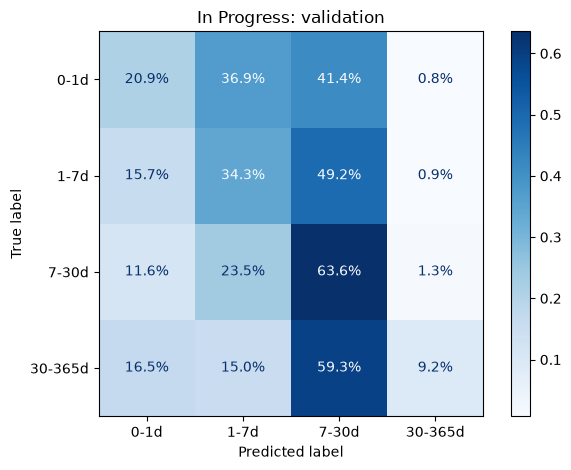

In [24]:
ConfusionMatrixDisplay.from_predictions(
    y_valid, y_valid_pred, labels=CLASS_LABELS,
    normalize="true", values_format=".1%", cmap="Blues",
)
plt.title("In Progress: validation")
plt.tight_layout()
plt.show()

In [25]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score


majority_class = y_train.mode().iloc[0]
rows = []

for split, X, y in (("train", X_train, y_train), ("validation", X_valid, y_valid), ("test", X_test, y_test)):
    predictions = classifier.predict(X).ravel()
    baseline_predictions = [majority_class] * len(y)

    for model_name, pred in (("CatBoost", predictions), ("Majority baseline", baseline_predictions)):
        rows.append({
            "Split": split,
            "Model": model_name,
            "Accuracy": accuracy_score(y, pred),
            "Balanced accuracy": balanced_accuracy_score(y, pred),
            "Macro F1": f1_score(y, pred, average="macro", zero_division=0),
        })

metrics_in_progress_df = pd.DataFrame(rows).set_index(["Split", "Model"])
metrics_in_progress_df.round(3)

Accuracy  Balanced accuracy  Macro F1
Split      Model                                                   
train      CatBoost              0.418              0.377     0.358
           Majority baseline     0.293              0.250     0.113
validation CatBoost              0.355              0.320     0.303
           Majority baseline     0.303              0.250     0.116
test       CatBoost              0.366              0.328     0.312
           Majority baseline     0.292              0.250     0.113

## In Progress — классификатор с текстовыми эмбеддингами

Эксперимент: первые 512 токенов текста. Комментарии могут содержать более поздние правки; качество следует трактовать с этим ограничением.

In [30]:
import numpy as np
from sentence_transformers import SentenceTransformer

embedding_model = SentenceTransformer("BAAI/bge-small-en-v1.5")
embedding_model.max_seq_length = 512

train_embeddings = embedding_model.encode(
    train_df["Description_And_Comments"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
)
valid_embeddings = embedding_model.encode(
    valid_df["Description_And_Comments"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
)
test_embeddings = embedding_model.encode(
    test_df["Description_And_Comments"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
)

print("Train:", train_embeddings.shape)
print("Validation:", valid_embeddings.shape)
print("Test:", test_embeddings.shape)

Batches: 100%|██████████| 482/482 [07:06<00:00,  1.13it/s]

Train: (70935, 384)
Validation: (14586, 384)
Test: (15418, 384)


In [31]:
embedding_columns = [f"embedding_{i}" for i in range(train_embeddings.shape[1])]

X_train_text = pd.concat(
    [X_train, pd.DataFrame(train_embeddings, index=X_train.index, columns=embedding_columns)],
    axis=1,
)
X_valid_text = pd.concat(
    [X_valid, pd.DataFrame(valid_embeddings, index=X_valid.index, columns=embedding_columns)],
    axis=1,
)
X_test_text = pd.concat(
    [X_test, pd.DataFrame(test_embeddings, index=X_test.index, columns=embedding_columns)],
    axis=1,
)

print("Train:", X_train_text.shape)
print("Validation:", X_valid_text.shape)
print("Test:", X_test_text.shape)

Train: (70935, 391)
Validation: (14586, 391)
Test: (15418, 391)


In [32]:
classifier_with_text = CatBoostClassifier(
    iterations=1000,
    depth=6,
    learning_rate=0.05,
    loss_function="MultiClass",
    cat_features=CATEGORICAL_FEATURES,
    random_seed=42,
    allow_writing_files=False,
)

classifier_with_text.fit(
    X_train_text,
    y_train,
    eval_set=(X_valid_text, y_valid),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=100,
)

0:	learn: 1.3787243	test: 1.3824538	best: 1.3824538 (0)	total: 156ms	remaining: 2m 35s
100:	learn: 1.2604883	test: 1.3143808	best: 1.3143808 (100)	total: 14.6s	remaining: 2m 9s
200:	learn: 1.2405300	test: 1.3045736	best: 1.3045736 (200)	total: 29.3s	remaining: 1m 56s
300:	learn: 1.2218598	test: 1.2981650	best: 1.2981650 (300)	total: 43.7s	remaining: 1m 41s
400:	learn: 1.2057148	test: 1.2955395	best: 1.2955395 (400)	total: 58.3s	remaining: 1m 27s
500:	learn: 1.1912472	test: 1.2944344	best: 1.2944344 (500)	total: 1m 19s	remaining: 1m 19s
600:	learn: 1.1774810	test: 1.2937249	best: 1.2936379 (592)	total: 1m 33s	remaining: 1m 2s
700:	learn: 1.1643089	test: 1.2926336	best: 1.2926336 (700)	total: 1m 48s	remaining: 46.2s
800:	learn: 1.1516993	test: 1.2925762	best: 1.2924359 (778)	total: 2m 3s	remaining: 30.6s
900:	learn: 1.1390239	test: 1.2922874	best: 1.2922193 (897)	total: 2m 18s	remaining: 15.2s
999:	learn: 1.1267542	test: 1.2921470	best: 1.2920741 (992)	total: 2m 32s	remaining: 0us

bestT

CatBoostClassifier(allow_writing_files=False, cat_features=['Project_ID', 'Priority_At_Snapshot', 'Type_At_Snapshot'], depth=6, iterations=1000, learning_rate=0.05, loss_function='MultiClass', random_seed=42)

In [33]:
pred_without_text = classifier.predict(X_valid).ravel()
pred_with_text = classifier_with_text.predict(X_valid_text).ravel()

comparison = pd.DataFrame(
    {
        "Without text": {
            "Accuracy": accuracy_score(y_valid, pred_without_text),
            "Balanced accuracy": balanced_accuracy_score(y_valid, pred_without_text),
            "Macro F1": f1_score(y_valid, pred_without_text, average="macro", zero_division=0),
        },
        "With embeddings": {
            "Accuracy": accuracy_score(y_valid, pred_with_text),
            "Balanced accuracy": balanced_accuracy_score(y_valid, pred_with_text),
            "Macro F1": f1_score(y_valid, pred_with_text, average="macro", zero_division=0),
        },
    }
).T

comparison.round(3)

,Accuracy,Balanced accuracy,Macro F1
Without text,0.355,0.320,0.303
With embeddings,0.372,0.344,0.337


In [34]:
print(
    classification_report(
        y_valid,
        pred_with_text,
        labels=CLASS_LABELS,
        digits=3,
        zero_division=0,
    )
)

              precision    recall  f1-score   support

        0-1d      0.359     0.298     0.326      3197
        1-7d      0.353     0.362     0.358      4216
       7-30d      0.369     0.588     0.454      4415
     30-365d      0.616     0.127     0.211      2758

    accuracy                          0.372     14586
   macro avg      0.424     0.344     0.337     14586
weighted avg      0.409     0.372     0.352     14586



In [35]:
embedding_columns = [
    f"embedding_{i}"
    for i in range(train_embeddings.shape[1])
]

output_dir = project_path.artifacts / "in_progress_embeddings"
output_dir.mkdir(parents=True, exist_ok=True)

for split_name, frame, embeddings in (
    ("train", train_df, train_embeddings),
    ("validation", valid_df, valid_embeddings),
    ("test", test_df, test_embeddings),
):
    path = output_dir / f"{split_name}.pkl"

    if path.exists():
        raise FileExistsError(f"Файл уже существует: {path}")

    embedding_df = pd.DataFrame(
        embeddings,
        index=frame.index,
        columns=embedding_columns,
    )

    result_df = pd.concat([frame, embedding_df], axis=1)
    result_df.to_pickle(path)

    print(f"Сохранено: {path}, размер: {result_df.shape}")

Сохранено: D:\PROJECTS\average_task_performance\artifacts\in_progress_embeddings\train.pkl, размер: (70935, 398)
Сохранено: D:\PROJECTS\average_task_performance\artifacts\in_progress_embeddings\validation.pkl, размер: (14586, 398)
Сохранено: D:\PROJECTS\average_task_performance\artifacts\in_progress_embeddings\test.pkl, размер: (15418, 398)
